# Joint Autocorrelation Analysis

Compare temporal coherence of joint angle trajectories across datasets. For each joint, compute the autocorrelation function averaged across clips, then summarize with the autocorrelation time (lag at which autocorrelation drops below 1/e).

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from pathlib import Path

from scamper.analysis.discriminator.data_loading import (
    load_h5_dataset,
    list_h5_datasets,
)

# ============ CONFIGURATION ============
DATASET_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_goldenrodent_jax_fullclips_latents.h5"
REFERENCE_DATASET = "encoder_decoder_qpos"
JOINT_ANGLE_START = 7
EXCLUDE_DATASETS = {"original_qpos"}
SAVE_DIR = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation")

In [24]:
# Load raw qpos for autocorrelation (need full time series, not transitions)
available = list_h5_datasets(DATASET_PATH)
ac_generated_names = [
    ds for ds in available
    if ds.endswith("_qpos")
    and ds != REFERENCE_DATASET
    and ds not in EXCLUDE_DATASETS
    and ds != "prior_predicted_logvar_qpos"
]

ac_label_map = {
    "encoder_decoder_qpos": "Imitation",
    "prior_deterministic_qpos": "$\\sigma$=0.00",
    "prior_logvar_-4_qpos": "$\\sigma$=0.14",
    "prior_logvar_-3_qpos": "$\\sigma$=0.22",
    "prior_logvar_-2_qpos": "$\\sigma$=0.37",
    "prior_logvar_-1_qpos": "$\\sigma$=0.61",
    "prior_logvar_-0.5_qpos": "$\\sigma$=0.78",
    "prior_logvar_0_qpos": "$\\sigma$=1.00",
}

ac_datasets = [REFERENCE_DATASET] + ac_generated_names

ac_qpos = {}
for name in ac_datasets:
    data = load_h5_dataset(DATASET_PATH, name)
    ac_qpos[name] = data[:, :, JOINT_ANGLE_START:]  # (num_clips, num_steps, 67)
    print(f"  {name}: {ac_qpos[name].shape}")

  encoder_decoder_qpos: (842, 490, 67)
  prior_deterministic_qpos: (842, 490, 67)
  prior_logvar_-0.5_qpos: (842, 490, 67)
  prior_logvar_-1_qpos: (842, 490, 67)
  prior_logvar_-2_qpos: (842, 490, 67)
  prior_logvar_-3_qpos: (842, 490, 67)
  prior_logvar_-4_qpos: (842, 490, 67)
  prior_logvar_0_qpos: (842, 490, 67)


In [25]:
def compute_autocorrelation_per_clip(joints: np.ndarray, max_lag: int) -> np.ndarray:
    """Compute autocorrelation per clip (averaged across joints).

    Args:
        joints: Shape (num_clips, num_steps, num_joints).
        max_lag: Maximum lag to compute.

    Returns:
        Per-clip autocorrelation curves of shape (num_clips, max_lag + 1).
    """
    num_clips, num_steps, num_joints = joints.shape
    max_lag = min(max_lag, num_steps - 1)

    centered = joints - joints.mean(axis=1, keepdims=True)
    var = np.sum(centered ** 2, axis=1) / num_steps  # (num_clips, num_joints)

    ac_curves = np.zeros((num_clips, num_joints, max_lag + 1))
    for lag in range(max_lag + 1):
        if lag == 0:
            ac_curves[:, :, lag] = 1.0
        else:
            cov = np.sum(centered[:, :num_steps - lag, :] * centered[:, lag:, :], axis=1) / (num_steps - lag)
            ac_curves[:, :, lag] = np.where(var > 1e-12, cov / var, 0.0)

    # Average across joints, keep per-clip: (num_clips, max_lag + 1)
    return ac_curves.mean(axis=1)


def autocorrelation_time(ac_curve: np.ndarray, threshold: float = 1.0 / np.e) -> float:
    """Find the lag at which autocorrelation drops below threshold."""
    below = np.where(ac_curve < threshold)[0]
    return int(below[0]) if len(below) > 0 else len(ac_curve) - 1


MAX_LAG = 200

# Compute per-clip autocorrelation, then mean/std across clips
ac_stats = {}  # name -> {"mean": ..., "std": ...}
ac_times = {}
ac_times_std = {}

for name in ac_datasets:
    per_clip = compute_autocorrelation_per_clip(ac_qpos[name], MAX_LAG)
    mean_curve = per_clip.mean(axis=0)
    std_curve = per_clip.std(axis=0)

    ac_stats[name] = {"mean": mean_curve, "std": std_curve}
    ac_times[name] = autocorrelation_time(mean_curve)

    # Per-clip autocorrelation times for uncertainty
    per_clip_times = np.array([autocorrelation_time(c) for c in per_clip])
    ac_times_std[name] = per_clip_times.std()

    label = ac_label_map.get(name, name)
    print(f"{label}: autocorrelation time = {ac_times[name]} +/- {ac_times_std[name]:.1f} steps")

Imitation: autocorrelation time = 58 +/- 14.7 steps
$\sigma$=0.00: autocorrelation time = 54 +/- 14.1 steps
$\sigma$=0.78: autocorrelation time = 47 +/- 11.9 steps
$\sigma$=0.61: autocorrelation time = 49 +/- 12.0 steps
$\sigma$=0.37: autocorrelation time = 51 +/- 12.5 steps
$\sigma$=0.22: autocorrelation time = 53 +/- 13.2 steps
$\sigma$=0.14: autocorrelation time = 54 +/- 14.2 steps
$\sigma$=1.00: autocorrelation time = 44 +/- 11.1 steps


/tmp/ipykernel_4086257/2819143503.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("viridis", n_gen)


Saved autocorrelation curves


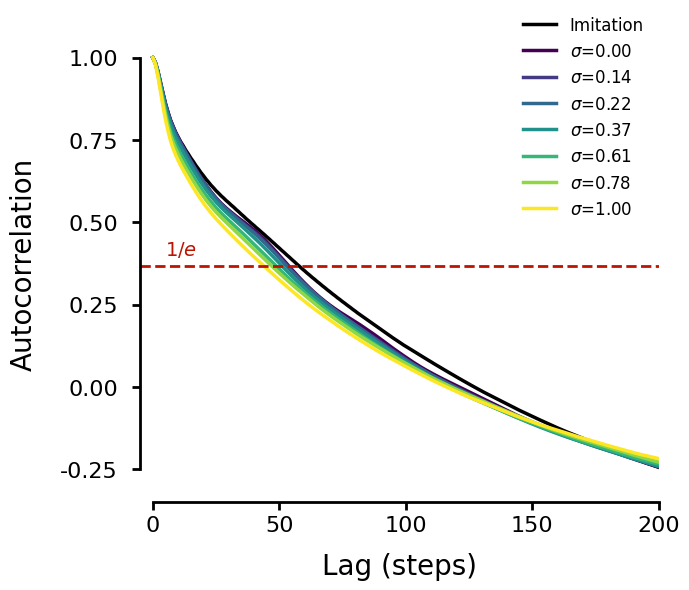

In [26]:
# Color palette: Imitation in black, generated in a colormap
import matplotlib.cm as cm

n_gen = len(ac_generated_names)
cmap = cm.get_cmap("viridis", n_gen)

# Sort generated names by sigma value
def ac_sort_key(name):
    lbl = ac_label_map.get(name, "")
    val = lbl.replace("$\\sigma$=", "")
    try:
        return float(val)
    except ValueError:
        return 999.0

ac_gen_sorted = sorted(ac_generated_names, key=ac_sort_key)

# Assign colors
ac_colors = {REFERENCE_DATASET: "black"}
for i, name in enumerate(ac_gen_sorted):
    ac_colors[name] = cmap(i)

# Plot order: enc-dec first, then sorted generated
ac_plot_order = [REFERENCE_DATASET] + ac_gen_sorted

lags = np.arange(MAX_LAG + 1)
red_color = tuple(c / 255 for c in (189, 19, 0))

fig, ax = plt.subplots(figsize=(7, 6))

for name in ac_plot_order:
    label = ac_label_map.get(name, name)
    mean = ac_stats[name]["mean"]
    color = ac_colors[name]

    ax.plot(lags, mean, linewidth=2.5, color=color, label=label)

ax.set_xlabel("Lag (steps)", fontsize=20, labelpad=12)
ax.set_ylabel("Autocorrelation", fontsize=20, labelpad=16)
ax.tick_params(labelsize=16, width=2, length=6)
ax.tick_params(axis="y", pad=10)
ax.set_ylim(-0.35, 1.1)
ax.set_xlim(-5, MAX_LAG)

# Set y ticks
base_yticks = [-0.25, 0.0, 0.25, 0.5, 0.75, 1.0]
ax.set_yticks(base_yticks)
ax.set_yticklabels([f"{t:.2f}" for t in base_yticks])

sns.despine(ax=ax)

# Trim spines to tick range — they won't meet since x starts at 0 but y starts at -0.25
xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax.spines["left"].set_bounds(base_yticks[0], base_yticks[-1])

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

# 1/e threshold line with label sitting above it
ax.axhline(1.0 / np.e, color=red_color, linestyle="--", alpha=1.0, linewidth=2)
ax.text(5, 1.0 / np.e + 0.02, "$1/e$", color=red_color, fontsize=14, va="bottom")

ax.legend(fontsize=12, frameon=False, loc="upper right", bbox_to_anchor=(1.0, 1.05))

plt.tight_layout()
SAVE_DIR.mkdir(parents=True, exist_ok=True)
for fmt in ("pdf", "svg", "png"):
    fig.savefig(SAVE_DIR / f"autocorrelation_curves.{fmt}", bbox_inches="tight", dpi=150)
print(f"Saved autocorrelation curves")
plt.show()

In [27]:
# Min autocorrelation (mean curve) for each dataset
for name in ac_plot_order:
    label = ac_label_map.get(name, name)
    min_val = ac_stats[name]["mean"].min()
    min_lag = ac_stats[name]["mean"].argmin()
    print(f"{label:>20s}: min autocorrelation = {min_val:.4f} at lag {min_lag}")

           Imitation: min autocorrelation = -0.2443 at lag 200
       $\sigma$=0.00: min autocorrelation = -0.2433 at lag 200
       $\sigma$=0.14: min autocorrelation = -0.2401 at lag 200
       $\sigma$=0.22: min autocorrelation = -0.2422 at lag 200
       $\sigma$=0.37: min autocorrelation = -0.2407 at lag 200
       $\sigma$=0.61: min autocorrelation = -0.2344 at lag 200
       $\sigma$=0.78: min autocorrelation = -0.2285 at lag 200
       $\sigma$=1.00: min autocorrelation = -0.2177 at lag 200


/tmp/ipykernel_4086257/1082365622.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=ac_labels, x=ac_values, palette=colors, ax=ax)


Saved autocorrelation time bar plot


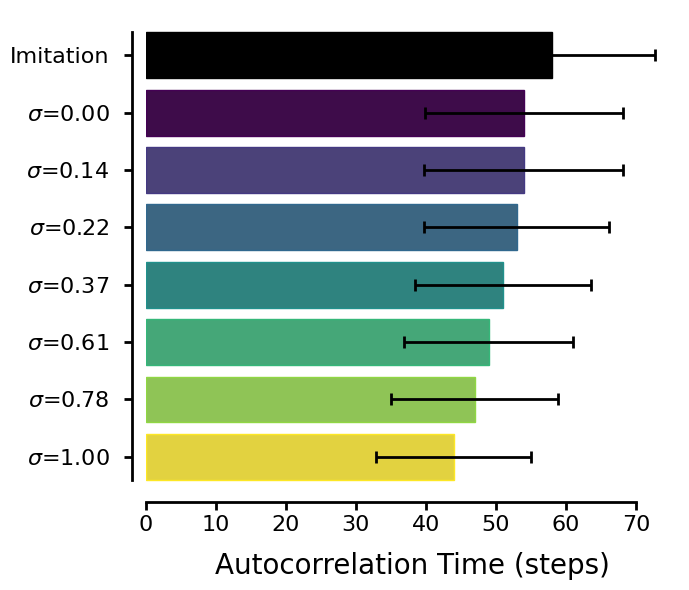

In [28]:
# Bar plot of autocorrelation times
ac_bar_order = [REFERENCE_DATASET] + ac_gen_sorted
ac_bar_order = [n for n in ac_bar_order if n in ac_times]

ac_labels = [ac_label_map.get(n, n) for n in ac_bar_order]
ac_values = [ac_times[n] for n in ac_bar_order]
ac_stds = [ac_times_std[n] for n in ac_bar_order]
colors = [ac_colors[n] for n in ac_bar_order]

fig, ax = plt.subplots(figsize=(7, 6))

sns.barplot(y=ac_labels, x=ac_values, palette=colors, ax=ax)

# Remove black outlines — set edgecolor to match facecolor
for patch, c in zip(ax.patches, colors):
    patch.set_edgecolor(c)

# Add error bars
bar_positions = sorted(
    [patch.get_y() + patch.get_height() / 2 for patch in ax.patches]
)
ax.errorbar(
    ac_values, bar_positions, xerr=ac_stds,
    fmt="none", ecolor="black", capsize=4, capthick=2, linewidth=2,
)

ax.set_xlabel("Autocorrelation Time (steps)", fontsize=20, labelpad=12)
ax.set_ylabel("")
ax.tick_params(labelsize=16, width=2, length=6)
ax.tick_params(axis="y", pad=10)

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 10))

xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])

bar_positions_raw = sorted([p.get_y() for p in ax.patches])
ax.spines["left"].set_bounds(bar_positions_raw[0], bar_positions_raw[-1] + ax.patches[0].get_height())

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()
for fmt in ("pdf", "svg", "png"):
    fig.savefig(SAVE_DIR / f"autocorrelation_time.{fmt}", bbox_inches="tight")
print(f"Saved autocorrelation time bar plot")
plt.show()

# Joint Autocorrelation Analysis (Distill)

Compare temporal coherence of joint angle trajectories across datasets from the distill checkpoint. For each joint, compute the autocorrelation function averaged across clips, then summarize with the autocorrelation time (lag at which autocorrelation drops below 1/e).

In [29]:
# ============ DISTILL CONFIGURATION ============
DISTILL_DATASET_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_distill_15.h5"
DISTILL_REFERENCE_DATASET = "student_encoder_decoder_qpos"

# Load raw qpos for autocorrelation (need full time series, not transitions)
distill_available = list_h5_datasets(DISTILL_DATASET_PATH)
distill_ac_generated_names = [
    ds for ds in distill_available
    if ds.endswith("_qpos")
    and ds != DISTILL_REFERENCE_DATASET
    and ds not in EXCLUDE_DATASETS
    and ds != "prior_predicted_logvar_qpos"
]

distill_ac_label_map = {
    "student_encoder_decoder_qpos": "Student Imitation",
    "teacher_qpos": "Teacher Imitation",
    "encoder_decoder_qpos": "Imitation Rollout",
    "prior_deterministic_qpos": "$\\sigma$=0.00",
    "prior_logvar_-4_qpos": "$\\sigma$=0.14",
    "prior_logvar_-3_qpos": "$\\sigma$=0.22",
    "prior_logvar_-2_qpos": "$\\sigma$=0.37",
    "prior_logvar_-1_qpos": "$\\sigma$=0.61",
    "prior_logvar_-0.5_qpos": "$\\sigma$=0.78",
    "prior_logvar_0_qpos": "$\\sigma$=1.00",
}

distill_ac_datasets = [DISTILL_REFERENCE_DATASET] + distill_ac_generated_names

distill_ac_qpos = {}
for name in distill_ac_datasets:
    data = load_h5_dataset(DISTILL_DATASET_PATH, name)
    distill_ac_qpos[name] = data[:, :, JOINT_ANGLE_START:]
    print(f"  {name}: {distill_ac_qpos[name].shape}")

  student_encoder_decoder_qpos: (842, 490, 67)
  prior_deterministic_qpos: (842, 490, 67)
  prior_logvar_-0.5_qpos: (842, 490, 67)
  prior_logvar_-1_qpos: (842, 490, 67)
  prior_logvar_-2_qpos: (842, 490, 67)
  prior_logvar_-3_qpos: (842, 490, 67)
  prior_logvar_-4_qpos: (842, 490, 67)
  prior_logvar_0_qpos: (842, 490, 67)
  teacher_qpos: (842, 490, 67)


In [30]:
# Compute per-clip autocorrelation for distill datasets
distill_ac_stats = {}
distill_ac_times = {}
distill_ac_times_std = {}

for name in distill_ac_datasets:
    per_clip = compute_autocorrelation_per_clip(distill_ac_qpos[name], MAX_LAG)
    mean_curve = per_clip.mean(axis=0)
    std_curve = per_clip.std(axis=0)

    distill_ac_stats[name] = {"mean": mean_curve, "std": std_curve}
    distill_ac_times[name] = autocorrelation_time(mean_curve)

    per_clip_times = np.array([autocorrelation_time(c) for c in per_clip])
    distill_ac_times_std[name] = per_clip_times.std()

    label = distill_ac_label_map.get(name, name)
    print(f"{label}: autocorrelation time = {distill_ac_times[name]} +/- {distill_ac_times_std[name]:.1f} steps")

Student Imitation: autocorrelation time = 57 +/- 14.7 steps
$\sigma$=0.00: autocorrelation time = 76 +/- 13.2 steps
$\sigma$=0.78: autocorrelation time = 62 +/- 22.9 steps
$\sigma$=0.61: autocorrelation time = 57 +/- 21.6 steps
$\sigma$=0.37: autocorrelation time = 67 +/- 16.7 steps
$\sigma$=0.22: autocorrelation time = 70 +/- 15.0 steps
$\sigma$=0.14: autocorrelation time = 73 +/- 14.1 steps
$\sigma$=1.00: autocorrelation time = 62 +/- 21.0 steps
Teacher Imitation: autocorrelation time = 55 +/- 12.7 steps


/tmp/ipykernel_4086257/1759657286.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  distill_cmap = cm.get_cmap("viridis", distill_n_gen)


Saved distill autocorrelation curves


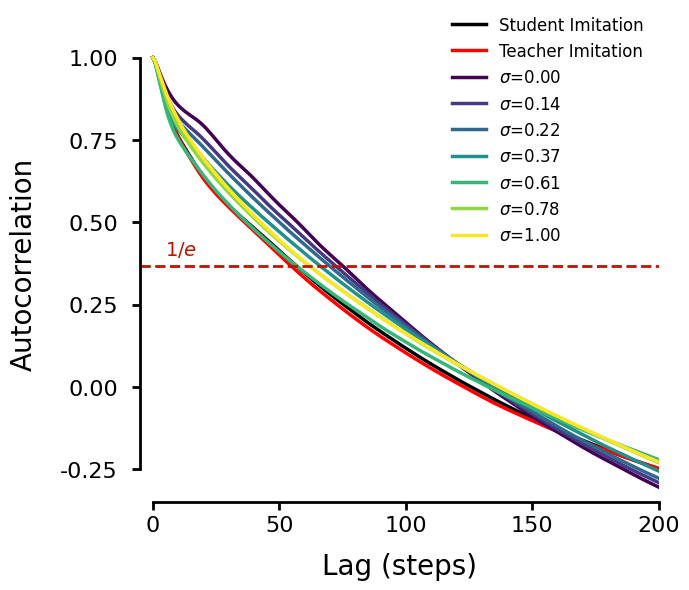

In [31]:
# Color palette: Student Imitation in black, Teacher in red, generated in viridis
import matplotlib.cm as cm

DISTILL_TEACHER_DATASET = "teacher_qpos"

distill_ac_gen_no_teacher = [n for n in distill_ac_generated_names if n != DISTILL_TEACHER_DATASET]
distill_n_gen = len(distill_ac_gen_no_teacher)
distill_cmap = cm.get_cmap("viridis", distill_n_gen)

def distill_ac_sort_key(name):
    lbl = distill_ac_label_map.get(name, "")
    val = lbl.replace("$\\sigma$=", "")
    try:
        return float(val)
    except ValueError:
        return 999.0

distill_ac_gen_sorted = sorted(distill_ac_gen_no_teacher, key=distill_ac_sort_key)

distill_ac_colors = {DISTILL_REFERENCE_DATASET: "black", DISTILL_TEACHER_DATASET: "red"}
for i, name in enumerate(distill_ac_gen_sorted):
    distill_ac_colors[name] = distill_cmap(i)

distill_ac_plot_order = [DISTILL_REFERENCE_DATASET, DISTILL_TEACHER_DATASET] + distill_ac_gen_sorted

lags = np.arange(MAX_LAG + 1)
red_color = tuple(c / 255 for c in (189, 19, 0))

fig, ax = plt.subplots(figsize=(7, 6))

for name in distill_ac_plot_order:
    label = distill_ac_label_map.get(name, name)
    mean = distill_ac_stats[name]["mean"]
    color = distill_ac_colors[name]

    ax.plot(lags, mean, linewidth=2.5, color=color, label=label)

ax.set_xlabel("Lag (steps)", fontsize=20, labelpad=12)
ax.set_ylabel("Autocorrelation", fontsize=20, labelpad=16)
ax.tick_params(labelsize=16, width=2, length=6)
ax.tick_params(axis="y", pad=10)
ax.set_ylim(-0.35, 1.1)
ax.set_xlim(-5, MAX_LAG)

base_yticks = [-0.25, 0.0, 0.25, 0.5, 0.75, 1.0]
ax.set_yticks(base_yticks)
ax.set_yticklabels([f"{t:.2f}" for t in base_yticks])

sns.despine(ax=ax)

xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax.spines["left"].set_bounds(base_yticks[0], base_yticks[-1])

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

ax.axhline(1.0 / np.e, color=red_color, linestyle="--", alpha=1.0, linewidth=2)
ax.text(5, 1.0 / np.e + 0.02, "$1/e$", color=red_color, fontsize=14, va="bottom")

ax.legend(fontsize=12, frameon=False, loc="upper right", bbox_to_anchor=(1.0, 1.05))

plt.tight_layout()
SAVE_DIR.mkdir(parents=True, exist_ok=True)
for fmt in ("pdf", "svg", "png"):
    fig.savefig(SAVE_DIR / f"autocorrelation_curves_distill.{fmt}", bbox_inches="tight", dpi=150)
print(f"Saved distill autocorrelation curves")
plt.show()

In [32]:
# Min autocorrelation (mean curve) for each distill dataset
for name in distill_ac_plot_order:
    label = distill_ac_label_map.get(name, name)
    min_val = distill_ac_stats[name]["mean"].min()
    min_lag = distill_ac_stats[name]["mean"].argmin()
    print(f"{label:>20s}: min autocorrelation = {min_val:.4f} at lag {min_lag}")

   Student Imitation: min autocorrelation = -0.2487 at lag 200
   Teacher Imitation: min autocorrelation = -0.2475 at lag 200
       $\sigma$=0.00: min autocorrelation = -0.3044 at lag 200
       $\sigma$=0.14: min autocorrelation = -0.2906 at lag 200
       $\sigma$=0.22: min autocorrelation = -0.2772 at lag 200
       $\sigma$=0.37: min autocorrelation = -0.2556 at lag 200
       $\sigma$=0.61: min autocorrelation = -0.2211 at lag 200
       $\sigma$=0.78: min autocorrelation = -0.2300 at lag 200
       $\sigma$=1.00: min autocorrelation = -0.2279 at lag 200


/tmp/ipykernel_4086257/3142870341.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=distill_ac_labels, x=distill_ac_values, palette=distill_bar_colors, ax=ax)


Saved distill autocorrelation time bar plot


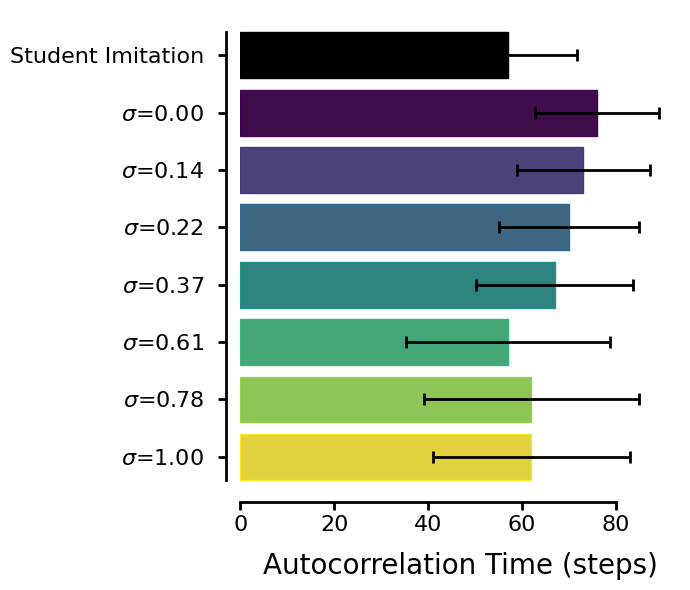

In [33]:
# Bar plot of distill autocorrelation times
distill_ac_bar_order = [DISTILL_REFERENCE_DATASET] + distill_ac_gen_sorted
distill_ac_bar_order = [n for n in distill_ac_bar_order if n in distill_ac_times]

distill_ac_labels = [distill_ac_label_map.get(n, n) for n in distill_ac_bar_order]
distill_ac_values = [distill_ac_times[n] for n in distill_ac_bar_order]
distill_ac_stds_list = [distill_ac_times_std[n] for n in distill_ac_bar_order]
distill_bar_colors = [distill_ac_colors[n] for n in distill_ac_bar_order]

fig, ax = plt.subplots(figsize=(7, 6))

sns.barplot(y=distill_ac_labels, x=distill_ac_values, palette=distill_bar_colors, ax=ax)

# Remove black outlines — set edgecolor to match facecolor
for patch, c in zip(ax.patches, distill_bar_colors):
    patch.set_edgecolor(c)

# Add error bars
bar_positions = sorted(
    [patch.get_y() + patch.get_height() / 2 for patch in ax.patches]
)
ax.errorbar(
    distill_ac_values, bar_positions, xerr=distill_ac_stds_list,
    fmt="none", ecolor="black", capsize=4, capthick=2, linewidth=2,
)

ax.set_xlabel("Autocorrelation Time (steps)", fontsize=20, labelpad=12)
ax.set_ylabel("")
ax.tick_params(labelsize=16, width=2, length=6)
ax.tick_params(axis="y", pad=10)

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 10))

xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])

bar_positions_raw = sorted([p.get_y() for p in ax.patches])
ax.spines["left"].set_bounds(bar_positions_raw[0], bar_positions_raw[-1] + ax.patches[0].get_height())

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()
for fmt in ("pdf", "svg", "png"):
    fig.savefig(SAVE_DIR / f"autocorrelation_time_distill.{fmt}", bbox_inches="tight")
print(f"Saved distill autocorrelation time bar plot")
plt.show()

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/autocorrelation_time_comparison.pdf and .svg


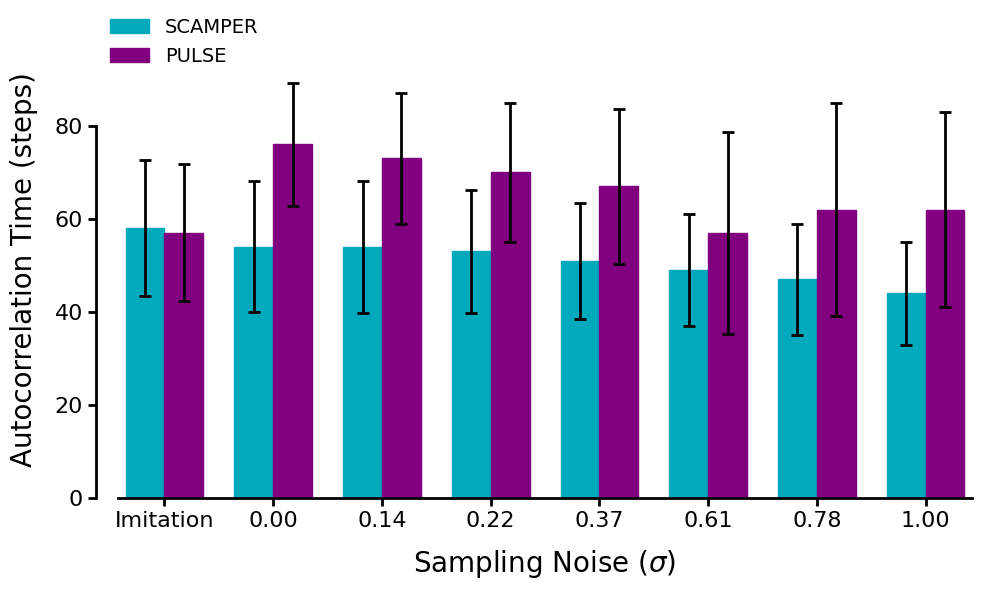

In [41]:
# Grouped vertical bar chart: SCAMPER vs PULSE autocorrelation times
# Include imitation reference + shared sigma labels
ac_sigma_label_map = {
    "prior_deterministic_qpos": "0.00",
    "prior_logvar_-4_qpos": "0.14",
    "prior_logvar_-3_qpos": "0.22",
    "prior_logvar_-2_qpos": "0.37",
    "prior_logvar_-1_qpos": "0.61",
    "prior_logvar_-0.5_qpos": "0.78",
    "prior_logvar_0_qpos": "1.00",
}
ac_sigma_names = list(ac_sigma_label_map.keys())

# X-axis labels: Imitation first, then sigma values
ac_x_labels = ["Imitation"] + list(ac_sigma_label_map.values())

# SCAMPER values: encoder_decoder_qpos (imitation) + prior sigmas
scamper_ac_vals = [ac_times[REFERENCE_DATASET]] + [ac_times[n] for n in ac_sigma_names]
scamper_ac_errs = [ac_times_std[REFERENCE_DATASET]] + [ac_times_std[n] for n in ac_sigma_names]

# PULSE values: student_encoder_decoder_qpos (imitation) + prior sigmas
pulse_ac_vals = [distill_ac_times[DISTILL_REFERENCE_DATASET]] + [distill_ac_times[n] for n in ac_sigma_names]
pulse_ac_errs = [distill_ac_times_std[DISTILL_REFERENCE_DATASET]] + [distill_ac_times_std[n] for n in ac_sigma_names]

# Colors
bar_rgb = (0, 170, 188)
bar_color = tuple(c / 255 for c in bar_rgb)
purple_rgb = (128, 0, 128)
purple_color = tuple(c / 255 for c in purple_rgb)

save_name_ac_cmp = "autocorrelation_time_comparison"

fig, ax = plt.subplots(figsize=(10, 6))

n = len(ac_x_labels)
x = np.arange(n) * 1.4  # spread out x positions
bar_width = 0.5

# SCAMPER bars
ax.bar(
    x - bar_width / 2,
    scamper_ac_vals,
    bar_width,
    color=bar_color,
    edgecolor=bar_color,
    label="SCAMPER",
)
ax.errorbar(
    x - bar_width / 2,
    scamper_ac_vals,
    yerr=scamper_ac_errs,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

# PULSE bars
ax.bar(
    x + bar_width / 2,
    pulse_ac_vals,
    bar_width,
    color=purple_color,
    edgecolor=purple_color,
    label="PULSE",
)
ax.errorbar(
    x + bar_width / 2,
    pulse_ac_vals,
    yerr=pulse_ac_errs,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

ax.set_xticks(x)
ax.set_xticklabels(ac_x_labels)
ax.set_xlim(x[0] - 0.7, x[-1] + 0.7)

y_max = max(
    max(v + e for v, e in zip(scamper_ac_vals, scamper_ac_errs)),
    max(v + e for v, e in zip(pulse_ac_vals, pulse_ac_errs)),
)
ax.set_ylim(0, y_max * 1.1)

ax.set_ylabel("Autocorrelation Time (steps)", fontsize=20, labelpad=12)
ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False, loc="center left", bbox_to_anchor=(-0.02, 1.0))

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 10))

yticks = ax.get_yticks()
ylim = ax.get_ylim()
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
ax.spines["left"].set_bounds(yticks[0], yticks[-1])

ax.spines["bottom"].set_bounds(x[0] - 0.6, x[-1] + 0.6)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

SAVE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(SAVE_DIR / f"{save_name_ac_cmp}.pdf", bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{save_name_ac_cmp}.svg", bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{save_name_ac_cmp}.png", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / save_name_ac_cmp}.pdf and .svg")

plt.show()

In [42]:
# Statistical significance: Welch's t-test on per-clip autocorrelation times
# SCAMPER vs PULSE for each sigma level + imitation
from scipy import stats

# Recompute per-clip autocorrelation times (needed for t-test, not just mean/std)
scamper_per_clip_ac_times = {}
pulse_per_clip_ac_times = {}

# Imitation
scamper_clips = compute_autocorrelation_per_clip(ac_qpos[REFERENCE_DATASET], MAX_LAG)
scamper_per_clip_ac_times["Imitation"] = np.array([autocorrelation_time(c) for c in scamper_clips])

pulse_clips = compute_autocorrelation_per_clip(distill_ac_qpos[DISTILL_REFERENCE_DATASET], MAX_LAG)
pulse_per_clip_ac_times["Imitation"] = np.array([autocorrelation_time(c) for c in pulse_clips])

# Prior sigmas
for name, label in ac_sigma_label_map.items():
    scamper_clips = compute_autocorrelation_per_clip(ac_qpos[name], MAX_LAG)
    scamper_per_clip_ac_times[label] = np.array([autocorrelation_time(c) for c in scamper_clips])

    pulse_clips = compute_autocorrelation_per_clip(distill_ac_qpos[name], MAX_LAG)
    pulse_per_clip_ac_times[label] = np.array([autocorrelation_time(c) for c in pulse_clips])

# Run Welch's t-test for each
print(f"{'Label':>12s}  {'SCAMPER':>16s}  {'PULSE':>16s}  {'t-stat':>8s}  {'p-value':>10s}  {'Sig?':>5s}")
print("-" * 80)

all_labels = ["Imitation"] + list(ac_sigma_label_map.values())
for label in all_labels:
    s = scamper_per_clip_ac_times[label]
    p = pulse_per_clip_ac_times[label]

    t_stat, p_val = stats.ttest_ind(s, p, equal_var=False)
    sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

    print(
        f"{label:>12s}  "
        f"{s.mean():6.1f} +/- {s.std():5.1f}  "
        f"{p.mean():6.1f} +/- {p.std():5.1f}  "
        f"{t_stat:8.2f}  "
        f"{p_val:10.2e}  "
        f"{sig:>5s}"
    )

       Label           SCAMPER             PULSE    t-stat     p-value   Sig?
--------------------------------------------------------------------------------
   Imitation    57.5 +/-  14.7    56.4 +/-  14.7      1.58    1.14e-01     ns
        0.00    52.3 +/-  14.1    75.4 +/-  13.2    -34.61   1.97e-198    ***
        0.14    51.7 +/-  14.2    72.3 +/-  14.1    -29.85   1.90e-157    ***
        0.22    52.1 +/-  13.2    70.2 +/-  15.0    -26.24   3.62e-127    ***
        0.37    50.8 +/-  12.5    66.3 +/-  16.7    -21.55    2.18e-90    ***
        0.61    48.8 +/-  12.0    57.0 +/-  21.6     -9.57    5.16e-21    ***
        0.78    47.5 +/-  11.9    62.7 +/-  22.9    -17.07    5.61e-59    ***
        1.00    44.6 +/-  11.1    63.8 +/-  21.0    -23.48   1.29e-101    ***


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/autocorrelation_time_comparison_sig.pdf and .svg


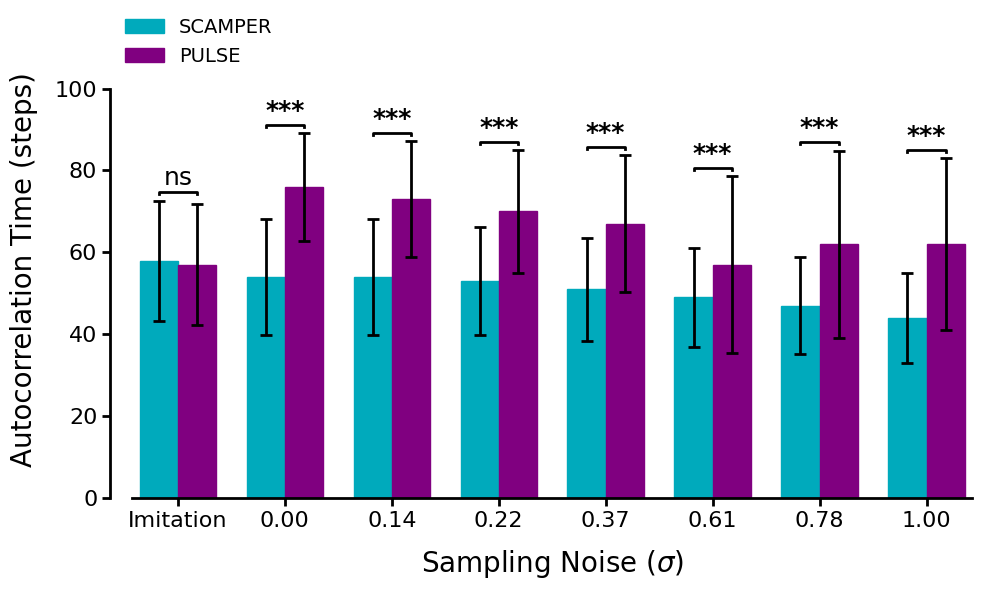

In [47]:
# Replot with significance brackets
save_name_ac_cmp_sig = "autocorrelation_time_comparison_sig"

fig, ax = plt.subplots(figsize=(10, 6))

n = len(ac_x_labels)
x = np.arange(n) * 1.4
bar_width = 0.5

# SCAMPER bars
ax.bar(
    x - bar_width / 2,
    scamper_ac_vals,
    bar_width,
    color=bar_color,
    edgecolor=bar_color,
    label="SCAMPER",
)
ax.errorbar(
    x - bar_width / 2,
    scamper_ac_vals,
    yerr=scamper_ac_errs,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

# PULSE bars
ax.bar(
    x + bar_width / 2,
    pulse_ac_vals,
    bar_width,
    color=purple_color,
    edgecolor=purple_color,
    label="PULSE",
)
ax.errorbar(
    x + bar_width / 2,
    pulse_ac_vals,
    yerr=pulse_ac_errs,
    fmt="none",
    ecolor="black",
    capsize=4,
    capthick=2,
    linewidth=2,
)

# Add significance brackets
all_labels = ["Imitation"] + list(ac_sigma_label_map.values())
for i, label in enumerate(all_labels):
    s = scamper_per_clip_ac_times[label]
    p = pulse_per_clip_ac_times[label]
    _, p_val = stats.ttest_ind(s, p, equal_var=False)
    sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

    # Height of bracket: above the taller error bar
    y_left = scamper_ac_vals[i] + scamper_ac_errs[i]
    y_right = pulse_ac_vals[i] + pulse_ac_errs[i]
    y_bracket = max(y_left, y_right) + 2

    x_left = x[i] - bar_width / 2
    x_right = x[i] + bar_width / 2

    # Draw bracket
    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_bracket - 0.5, y_bracket, y_bracket, y_bracket - 0.5],
        color="black",
        linewidth=2,
    )
    fw = "normal" if sig == "ns" else "bold"
    ax.text(
        x[i], y_bracket + 0.5, sig,
        ha="center", va="bottom", fontsize=18, fontweight=fw, color="black",
    )

ax.set_xticks(x)
ax.set_xticklabels(ac_x_labels)
ax.set_xlim(x[0] - 0.7, x[-1] + 0.7)

# Extend y-axis to fit brackets
y_max = max(
    max(v + e for v, e in zip(scamper_ac_vals, scamper_ac_errs)),
    max(v + e for v, e in zip(pulse_ac_vals, pulse_ac_errs)),
)
ax.set_ylim(0, y_max * 1.25)

ax.set_ylabel("Autocorrelation Time (steps)", fontsize=20, labelpad=12)
ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False, loc="center left", bbox_to_anchor=(-0.02, 1.0))

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 10))

yticks = ax.get_yticks()
ylim = ax.get_ylim()
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
ax.spines["left"].set_bounds(yticks[0], yticks[-1])

ax.spines["bottom"].set_bounds(x[0] - 0.6, x[-1] + 0.6)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

SAVE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(SAVE_DIR / f"{save_name_ac_cmp_sig}.pdf", bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{save_name_ac_cmp_sig}.svg", bbox_inches="tight")
fig.savefig(SAVE_DIR / f"{save_name_ac_cmp_sig}.png", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / save_name_ac_cmp_sig}.pdf and .svg")

plt.show()